# ASL Desktop 25-Word Model: BiGRU + Attention

This notebook preserves the V4 training run used by the desktop prototype. It is a historical runtime record, not the source of the current 50-class web model.

The original Kaggle output names shown in the executed cells were normalized when the required runtime artifacts were published under `models/word/desktop-25/`: `word_model.pt`, `word_model_meta.json`, and `word_labels.json`.

**25 everyday signs** — changes from V3:

| Property | V3 | V4 (this run) |
|---|---|---|
| Loss | Cross-entropy with label smoothing | Focal loss with label smoothing |
| Augmentation | Six techniques | Added mixup |
| Model | GRU final hidden state | GRU with attention pooling |
| Scheduler | ReduceLROnPlateau | CosineAnnealingWarmRestarts |
| Dropout | 0.3 | 0.4 |
| Weight decay | 0 | 1e-4 |
| Maximum epochs | 80 | 100 |
| Early-stopping patience | 12 | 15 |

The experiment aimed to reduce the V3 model's overconfident live predictions through stronger regularization and a more selective loss function.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from multiprocessing import Pool, cpu_count

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Cihaz: {device}")
print(f"PyTorch: {torch.__version__}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")

Cihaz: cuda
PyTorch: 2.10.0+cu128
GPU: Tesla T4


## 1. Ayarlar ve Landmark Secimi

In [2]:
# ============ AYARLAR ============

ASL_SIGNS_DIR = "/kaggle/input/asl-signs"
if not os.path.exists(ASL_SIGNS_DIR):
    ASL_SIGNS_DIR = "/kaggle/input/competitions/asl-signs"
if not os.path.exists(ASL_SIGNS_DIR):
    import glob
    candidates = glob.glob("/kaggle/input/*/train.csv")
    if candidates:
        ASL_SIGNS_DIR = os.path.dirname(candidates[0])

assert os.path.exists(os.path.join(ASL_SIGNS_DIR, "train.csv")), \
    "train.csv bulunamadi! Add Input -> Competition -> asl-signs"
print(f"Dataset yolu: {ASL_SIGNS_DIR}")

TARGET_WORDS = [
    "hello", "bye", "yes", "no", "please", "thankyou", "finish",
    "go", "drink", "give", "look", "wait", "sleep", "open", "talk",
    "mom", "dad", "child",
    "happy", "sad", "hungry", "sick",
    "home", "food", "water",
]

SEQUENCE_LENGTH = 30

# Landmark secimi (V3 ile ayni)
FACE_INDICES = [
    61, 185, 40, 39, 37, 0, 267, 269, 270, 409,
    291, 375, 321, 405, 314, 17,
    46, 53, 52, 65, 276, 283, 282, 295,
    33, 7, 163, 144, 362, 382, 381, 263,
    1, 2, 98, 327, 168, 197, 195, 5,
]
POSE_INDICES = list(range(25))

NUM_RIGHT_HAND = 21
NUM_LEFT_HAND = 21
NUM_FACE = len(FACE_INDICES)
NUM_POSE = len(POSE_INDICES)
NUM_LANDMARKS = NUM_RIGHT_HAND + NUM_LEFT_HAND + NUM_FACE + NUM_POSE
NUM_FEATURES = NUM_LANDMARKS * 3

# === V4 DEGISIKLIKLER ===
HIDDEN_SIZE = 128
NUM_LAYERS = 2
DROPOUT = 0.4          # V3: 0.3 -> V4: 0.4
BIDIRECTIONAL = True

BATCH_SIZE = 64
EPOCHS = 100            # V3: 80 -> V4: 100
LR = 0.001
PATIENCE = 15           # V3: 12 -> V4: 15
LABEL_SMOOTHING = 0.15  # V3: 0.1 -> V4: 0.15
GRAD_CLIP = 1.0
USE_AMP = True
WEIGHT_DECAY = 1e-4     # YENi
FOCAL_GAMMA = 2.0       # YENi — Focal Loss gamma
MIXUP_ALPHA = 0.2       # YENi — Mixup alpha
NUM_WORKERS = min(4, cpu_count())

OUTPUT_DIR = "/kaggle/working"

print(f"Hedef kelimeler ({len(TARGET_WORDS)}): {TARGET_WORDS}")
print(f"Sekans: {SEQUENCE_LENGTH} frame x {NUM_FEATURES} ozellik")
print(f"\nV4 Degisiklikler: dropout={DROPOUT}, label_smooth={LABEL_SMOOTHING}")
print(f"  focal_gamma={FOCAL_GAMMA}, mixup_alpha={MIXUP_ALPHA}, weight_decay={WEIGHT_DECAY}")

Dataset yolu: /kaggle/input/competitions/asl-signs
Hedef kelimeler (25): ['hello', 'bye', 'yes', 'no', 'please', 'thankyou', 'finish', 'go', 'drink', 'give', 'look', 'wait', 'sleep', 'open', 'talk', 'mom', 'dad', 'child', 'happy', 'sad', 'hungry', 'sick', 'home', 'food', 'water']
Sekans: 30 frame x 321 ozellik

V4 Degisiklikler: dropout=0.4, label_smooth=0.15
  focal_gamma=2.0, mixup_alpha=0.2, weight_decay=0.0001


## 2. Dataset Kesfi ve Filtreleme

In [3]:
train_csv = os.path.join(ASL_SIGNS_DIR, "train.csv")
train_df = pd.read_csv(train_csv)
all_signs = sorted(train_df['sign'].unique())
print(f"Toplam ornek: {len(train_df)}, Benzersiz kelimeler: {len(all_signs)}")

missing = [w for w in TARGET_WORDS if w not in all_signs]
if missing:
    raise ValueError(f"Bu kelimeler datasette YOK: {missing}")

target_df = train_df[train_df['sign'].isin(TARGET_WORDS)].copy()
print(f"\nFiltrelenmis ornek sayisi: {len(target_df)}")
print(target_df['sign'].value_counts().to_string())

Toplam ornek: 94477, Benzersiz kelimeler: 250

Filtrelenmis ornek sayisi: 9526
sign
look        414
bye         402
drink       400
home        395
mom         395
talk        394
food        392
sad         391
hello       390
go          388
finish      388
yes         386
hungry      385
water       384
please      384
sick        380
sleep       380
happy       379
dad         378
no          370
thankyou    357
open        354
child       348
wait        346
give        346


## 3. Veri Yukleme (V3 ile ayni)

In [4]:
def build_column_names():
    cols = []
    for i in range(NUM_RIGHT_HAND):
        cols.extend([f"x_right_hand_{i}", f"y_right_hand_{i}", f"z_right_hand_{i}"])
    for i in range(NUM_LEFT_HAND):
        cols.extend([f"x_left_hand_{i}", f"y_left_hand_{i}", f"z_left_hand_{i}"])
    for i in FACE_INDICES:
        cols.extend([f"x_face_{i}", f"y_face_{i}", f"z_face_{i}"])
    for i in POSE_INDICES:
        cols.extend([f"x_pose_{i}", f"y_pose_{i}", f"z_pose_{i}"])
    return cols

TARGET_COLS = build_column_names()

def normalize_multimodal(frame_data: np.ndarray) -> np.ndarray:
    data = frame_data.copy()
    pose_offset = (NUM_RIGHT_HAND + NUM_LEFT_HAND + NUM_FACE) * 3
    if 11 in POSE_INDICES and 12 in POSE_INDICES:
        idx_11 = POSE_INDICES.index(11)
        idx_12 = POSE_INDICES.index(12)
        left_shoulder = data[pose_offset + idx_11*3 : pose_offset + idx_11*3 + 3]
        right_shoulder = data[pose_offset + idx_12*3 : pose_offset + idx_12*3 + 3]
        if np.any(left_shoulder != 0) and np.any(right_shoulder != 0):
            center = (left_shoulder + right_shoulder) / 2.0
            width = np.linalg.norm(left_shoulder - right_shoulder)
            if width > 1e-6:
                reshaped = data.reshape(-1, 3)
                zero_mask = np.all(reshaped == 0, axis=1)
                reshaped[~zero_mask] = (reshaped[~zero_mask] - center) / width
                return reshaped.flatten().astype(np.float32)
    nonzero = data[data != 0]
    if len(nonzero) > 0:
        vmin, vmax = nonzero.min(), nonzero.max()
        rng = vmax - vmin
        if rng > 1e-6:
            data = np.where(data == 0, 0.0, (data - vmin) / rng)
    return data.astype(np.float32)

def load_parquet_multimodal(parquet_path: str) -> np.ndarray | None:
    try:
        df = pd.read_parquet(parquet_path)
    except Exception:
        return None
    
    if "type" in df.columns and "landmark_index" in df.columns:
        frames = sorted(df["frame"].unique())
        if len(frames) < 10:
            return None
        result = np.full((len(frames), NUM_FEATURES), np.nan, dtype=np.float32)
        for frame_idx, frame_num in enumerate(frames):
            fdf = df[df["frame"] == frame_num]
            offset = 0
            rh = fdf[fdf["type"] == "right_hand"].sort_values("landmark_index")
            if len(rh) >= NUM_RIGHT_HAND:
                result[frame_idx, offset:offset + NUM_RIGHT_HAND*3] = rh.head(NUM_RIGHT_HAND)[["x","y","z"]].values.flatten()
            offset += NUM_RIGHT_HAND * 3
            lh = fdf[fdf["type"] == "left_hand"].sort_values("landmark_index")
            if len(lh) >= NUM_LEFT_HAND:
                result[frame_idx, offset:offset + NUM_LEFT_HAND*3] = lh.head(NUM_LEFT_HAND)[["x","y","z"]].values.flatten()
            offset += NUM_LEFT_HAND * 3
            face = fdf[fdf["type"] == "face"].drop_duplicates(subset="landmark_index")
            if not face.empty:
                face_dict = dict(zip(face["landmark_index"].values, face[["x","y","z"]].values))
                for j, fi in enumerate(FACE_INDICES):
                    if fi in face_dict:
                        result[frame_idx, offset + j*3 : offset + j*3 + 3] = face_dict[fi]
            offset += NUM_FACE * 3
            pose = fdf[fdf["type"] == "pose"].drop_duplicates(subset="landmark_index")
            if not pose.empty:
                pose_dict = dict(zip(pose["landmark_index"].values, pose[["x","y","z"]].values))
                for j, pi in enumerate(POSE_INDICES):
                    if pi in pose_dict:
                        result[frame_idx, offset + j*3 : offset + j*3 + 3] = pose_dict[pi]
    elif any(c in df.columns for c in ["x_right_hand_0", "x_left_hand_0"]):
        available = [c for c in TARGET_COLS if c in df.columns]
        if len(available) < NUM_FEATURES * 0.3:
            return None
        result = np.full((len(df), NUM_FEATURES), np.nan, dtype=np.float32)
        for i, col in enumerate(TARGET_COLS):
            if col in df.columns:
                result[:, i] = df[col].values
    else:
        return None
    
    result_df = pd.DataFrame(result)
    result_df = result_df.ffill().bfill()
    result = result_df.values.astype(np.float32)
    result = np.nan_to_num(result, nan=0.0)
    valid_mask = np.any(result != 0, axis=1)
    result = result[valid_mask]
    if len(result) < 10:
        return None
    if len(result) >= SEQUENCE_LENGTH:
        indices = np.linspace(0, len(result) - 1, SEQUENCE_LENGTH, dtype=int)
        result = result[indices]
    else:
        padded = np.zeros((SEQUENCE_LENGTH, NUM_FEATURES), dtype=np.float32)
        padded[:len(result)] = result
        result = padded
    normalized = np.zeros_like(result)
    for i in range(SEQUENCE_LENGTH):
        if np.any(result[i] != 0):
            normalized[i] = normalize_multimodal(result[i])
    return normalized

print("Veri yukleme fonksiyonlari hazir.")

Veri yukleme fonksiyonlari hazir.


In [5]:
def _load_one(args):
    parquet_path, sign, label = args
    if not os.path.exists(parquet_path):
        return None
    seq = load_parquet_multimodal(parquet_path)
    if seq is not None:
        return (seq, label)
    return None

label_map = {word: i for i, word in enumerate(sorted(TARGET_WORDS))}
num_classes = len(label_map)

load_args = [
    (os.path.join(ASL_SIGNS_DIR, row['path']), row['sign'], label_map[row['sign']])
    for _, row in target_df.iterrows()
]

print(f"Toplam dosya: {len(load_args)}, Worker: {NUM_WORKERS}")
print("Yukleniyor...")

if NUM_WORKERS > 1:
    with Pool(NUM_WORKERS) as pool:
        results = pool.map(_load_one, load_args)
else:
    results = [_load_one(a) for a in load_args]

results = [r for r in results if r is not None]
X = np.array([r[0] for r in results], dtype=np.float32)
y = np.array([r[1] for r in results], dtype=np.int64)

inv_map = {v: k for k, v in label_map.items()}
print(f"\nSonuc: X={X.shape}, y={y.shape}")
print(f"Basarili: {len(results)}/{len(load_args)} ({len(results)/len(load_args):.1%})")

Toplam dosya: 9526, Worker: 4
Yukleniyor...

Sonuc: X=(7723, 30, 321), y=(7723,)
Basarili: 7723/9526 (81.1%)


## 4. Augmentation V4 (+Mixup)

In [6]:
class SignAugmenterV4:
    """V4: Daha agresif augmentation."""
    def __init__(self, p_speed=0.5, p_noise=0.6, p_mirror=0.3,
                 p_shift=0.4, p_finger_drop=0.4, p_temporal_crop=0.4):
        self.p_speed = p_speed
        self.p_noise = p_noise       # V3: 0.5 -> 0.6
        self.p_mirror = p_mirror
        self.p_shift = p_shift       # V3: 0.3 -> 0.4
        self.p_finger_drop = p_finger_drop  # V3: 0.3 -> 0.4
        self.p_temporal_crop = p_temporal_crop  # V3: 0.3 -> 0.4

    def __call__(self, seq):
        seq = seq.copy()
        if np.random.random() < self.p_speed:
            n = len(seq)
            speed = np.random.uniform(0.7, 1.3)  # V3: 0.8-1.2
            new_len = max(10, int(n * speed))
            src_idx = np.linspace(0, n - 1, new_len, dtype=int)
            stretched = seq[src_idx]
            if len(stretched) >= SEQUENCE_LENGTH:
                idx = np.linspace(0, len(stretched) - 1, SEQUENCE_LENGTH, dtype=int)
                seq = stretched[idx]
            else:
                padded = np.zeros_like(seq)
                padded[:len(stretched)] = stretched
                seq = padded
        if np.random.random() < self.p_noise:
            noise_scale = np.random.uniform(0.008, 0.03)  # V3: 0.005-0.02
            mask = (seq != 0).any(axis=1, keepdims=True)
            seq += np.random.normal(0, noise_scale, seq.shape).astype(np.float32) * mask
        if np.random.random() < self.p_mirror:
            rh_end = NUM_RIGHT_HAND * 3
            lh_end = rh_end + NUM_LEFT_HAND * 3
            right_hand = seq[:, :rh_end].copy()
            left_hand = seq[:, rh_end:lh_end].copy()
            seq[:, :rh_end] = left_hand
            seq[:, rh_end:lh_end] = right_hand
            for j in range(0, NUM_FEATURES, 3):
                seq[:, j] *= -1
        if np.random.random() < self.p_shift:
            shift = np.random.randint(-4, 5)  # V3: -3,4
            seq = np.roll(seq, shift, axis=0)
            if shift > 0: seq[:shift] = 0
            elif shift < 0: seq[shift:] = 0
        if np.random.random() < self.p_finger_drop:
            n_drop = np.random.randint(3, 10)  # V3: 3-8
            drop_indices = np.random.choice(NUM_LANDMARKS, n_drop, replace=False)
            for di in drop_indices:
                seq[:, di*3:(di+1)*3] = 0
        if np.random.random() < self.p_temporal_crop:
            crop = np.random.randint(2, 7)  # V3: 2-6
            if np.random.random() < 0.5: seq[:crop] = 0
            else: seq[-crop:] = 0
        return seq.astype(np.float32)


class SignDatasetV4(Dataset):
    """V4: Mixup destekli dataset."""
    def __init__(self, X, y, augmenter=None, mixup_alpha=0.0):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
        self.augmenter = augmenter
        self.X_np = X
        self.mixup_alpha = mixup_alpha

    def __len__(self): return len(self.y)

    def __getitem__(self, idx):
        if self.augmenter is not None:
            x = self.augmenter(self.X_np[idx])
            x = torch.tensor(x, dtype=torch.float32)
        else:
            x = self.X[idx]
        return x, self.y[idx]


def mixup_data(x, y, alpha=0.2):
    """Mixup augmentation — batch seviyesinde."""
    if alpha > 0:
        lam = np.random.beta(alpha, alpha)
    else:
        lam = 1.0
    batch_size = x.size(0)
    index = torch.randperm(batch_size, device=x.device)
    mixed_x = lam * x + (1 - lam) * x[index]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam


augmenter = SignAugmenterV4()
print("Augmentation V4 hazir (daha agresif + Mixup).")

Augmentation V4 hazir (daha agresif + Mixup).


## 5. Train/Val/Test Split

In [7]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print(f"Train: {X_train.shape[0]}, Val: {X_val.shape[0]}, Test: {X_test.shape[0]}")

train_counts = Counter(y_train)
class_weights = torch.tensor([1.0 / train_counts[i] for i in range(num_classes)], dtype=torch.float32)
class_weights = class_weights / class_weights.sum() * num_classes
class_weights = class_weights.to(device)

train_ds = SignDatasetV4(X_train, y_train, augmenter=augmenter, mixup_alpha=MIXUP_ALPHA)
val_ds = SignDatasetV4(X_val, y_val)
test_ds = SignDatasetV4(X_test, y_test)

train_dl = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS,   # ← EKLENDİ
    pin_memory=True,           # ← EKLENDİ (GPU transferi hızlanır)
    persistent_workers=True if NUM_WORKERS > 0 else False  # ← EKLENDİ
)
val_dl = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True if NUM_WORKERS > 0 else False
)
test_dl = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    persistent_workers=True if NUM_WORKERS > 0 else False
)

Train: 5406, Val: 1158, Test: 1159


## 6. Model V4 (Attention Pooling) + Focal Loss

In [8]:
class FocalLoss(nn.Module):
    """Focal Loss — overconfident tahminleri cezalandirir."""
    def __init__(self, gamma=2.0, weight=None, label_smoothing=0.0):
        super().__init__()
        self.gamma = gamma
        self.weight = weight
        self.label_smoothing = label_smoothing

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, weight=self.weight,
                                  label_smoothing=self.label_smoothing, reduction='none')
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()


class AttentionPooling(nn.Module):
    """Attention-based pooling — tum timestep'lere dikkat eder."""
    def __init__(self, hidden_size):
        super().__init__()
        self.attention = nn.Sequential(
            nn.Linear(hidden_size, hidden_size // 2),
            nn.Tanh(),
            nn.Linear(hidden_size // 2, 1),
        )

    def forward(self, x):
        # x: (batch, seq_len, hidden)
        scores = self.attention(x).squeeze(-1)  # (batch, seq_len)
        weights = F.softmax(scores, dim=1).unsqueeze(-1)  # (batch, seq_len, 1)
        return (x * weights).sum(dim=1)  # (batch, hidden)


class SignLanguageGRUv4(nn.Module):
    """V4: Bi-GRU + Attention Pooling."""
    def __init__(self, input_size=NUM_FEATURES, hidden_size=HIDDEN_SIZE,
                 num_layers=NUM_LAYERS, num_classes=None, dropout=DROPOUT,
                 bidirectional=BIDIRECTIONAL):
        super().__init__()
        assert num_classes is not None
        dir_factor = 2 if bidirectional else 1
        self.gru = nn.GRU(
            input_size=input_size, hidden_size=hidden_size,
            num_layers=num_layers, batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0,
            bidirectional=bidirectional,
        )
        self.attention_pool = AttentionPooling(hidden_size * dir_factor)
        self.dropout = nn.Dropout(dropout)
        self.fc = nn.Sequential(
            nn.Linear(hidden_size * dir_factor, hidden_size),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_size, num_classes),
        )

    def forward(self, x):
        out, _ = self.gru(x)  # (batch, seq, hidden*2)
        pooled = self.attention_pool(out)  # (batch, hidden*2)
        pooled = self.dropout(pooled)
        return self.fc(pooled)


model = SignLanguageGRUv4(num_classes=num_classes).to(device)
params = sum(p.numel() for p in model.parameters())
print(f"V4 Bi-GRU + Attention: {params:,} parametre")

V4 Bi-GRU + Attention: 711,962 parametre


## 7. Egitim (Focal Loss + Mixup + CosineAnnealing)

In [9]:
criterion = FocalLoss(gamma=FOCAL_GAMMA, weight=class_weights, label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(optimizer, T_0=20, T_mult=2)

use_amp = USE_AMP and device.type == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

best_val_loss = float("inf")
best_val_acc = 0.0
best_state = None
epochs_no_improve = 0
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

print(f"Loss: Focal (gamma={FOCAL_GAMMA}, smooth={LABEL_SMOOTHING}, weighted)")
print(f"Optimizer: AdamW (wd={WEIGHT_DECAY})")
print(f"AMP: {use_amp}")
print()
print(f"{'Epoch':>6} {'T.Loss':>8} {'T.Acc':>7} {'V.Loss':>8} {'V.Acc':>7}  {'LR':>10}")
print("-" * 56)

for epoch in range(1, EPOCHS + 1):
    model.train()
    t_loss, t_ok, t_n = 0, 0, 0
    for xb, yb in train_dl:
        xb, yb = xb.to(device), yb.to(device)
        # Mixup
        xb_mixed, ya, yb_mix, lam = mixup_data(xb, yb, MIXUP_ALPHA)
        optimizer.zero_grad()
        with torch.amp.autocast('cuda', enabled=use_amp):
            out = model(xb_mixed)
            loss = lam * criterion(out, ya) + (1 - lam) * criterion(out, yb_mix)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        t_loss += loss.item() * len(yb)
        t_ok += (out.argmax(1) == yb).sum().item()
        t_n += len(yb)

    scheduler.step()

    model.eval()
    v_loss, v_ok, v_n = 0, 0, 0
    with torch.no_grad():
        for xb, yb in val_dl:
            xb, yb = xb.to(device), yb.to(device)
            with torch.amp.autocast('cuda', enabled=use_amp):
                out = model(xb)
                v_loss += criterion(out, yb).item() * len(yb)
            v_ok += (out.argmax(1) == yb).sum().item()
            v_n += len(yb)

    tl, ta = t_loss / t_n, t_ok / t_n
    vl, va = v_loss / v_n, v_ok / v_n
    cur_lr = optimizer.param_groups[0]['lr']

    history["train_loss"].append(tl)
    history["val_loss"].append(vl)
    history["train_acc"].append(ta)
    history["val_acc"].append(va)

    print(f"  {epoch:>4} {tl:>8.4f} {ta:>6.1%} {vl:>8.4f} {va:>6.1%}  {cur_lr:.2e}")

    if vl < best_val_loss:
        best_val_loss = vl
        best_val_acc = va
        best_state = {k: v.clone() for k, v in model.state_dict().items()}
        epochs_no_improve = 0
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= PATIENCE:
            print(f"\nEarly stopping (epoch {epoch})")
            break

if best_state:
    model.load_state_dict(best_state)
print(f"\nEn iyi val acc: {best_val_acc:.1%}")

Loss: Focal (gamma=2.0, smooth=0.15, weighted)
Optimizer: AdamW (wd=0.0001)
AMP: True

 Epoch   T.Loss   T.Acc   V.Loss   V.Acc          LR
--------------------------------------------------------
     1   2.8058   5.9%   2.5496  15.7%  9.94e-04
     2   2.5719  11.0%   2.2801  25.4%  9.76e-04
     3   2.3355  15.6%   1.9675  35.9%  9.46e-04
     4   2.1065  19.9%   1.7287  47.3%  9.05e-04
     5   2.0086  23.6%   1.5464  52.6%  8.54e-04
     6   1.7976  23.7%   1.4418  56.9%  7.94e-04
     7   1.8165  27.2%   1.3502  59.6%  7.27e-04
     8   1.7416  29.6%   1.2721  65.2%  6.55e-04
     9   1.5965  31.1%   1.2058  66.1%  5.78e-04
    10   1.6278  31.3%   1.2182  65.5%  5.00e-04
    11   1.6316  28.5%   1.1828  68.3%  4.22e-04
    12   1.5474  32.6%   1.1142  67.7%  3.45e-04
    13   1.5807  36.5%   1.1236  68.2%  2.73e-04
    14   1.5565  36.9%   1.0857  69.7%  2.06e-04
    15   1.4822  29.9%   1.0515  71.8%  1.46e-04
    16   1.4565  35.7%   1.0305  72.3%  9.55e-05
    17   1.4578  33

## 8. Egitim Grafikleri

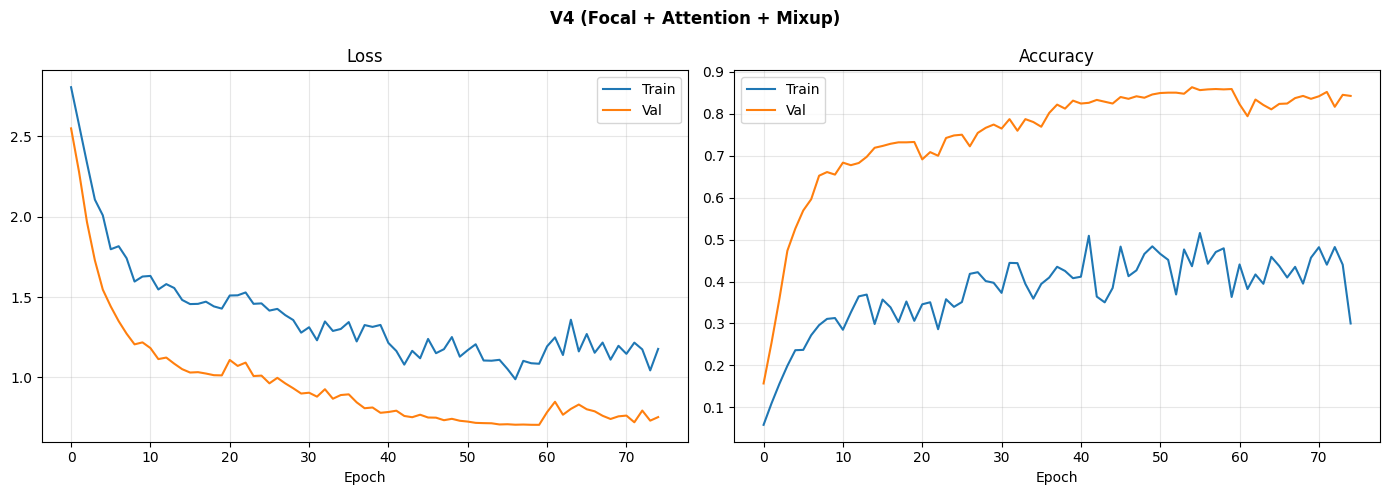

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
ax1.plot(history["train_loss"], label="Train")
ax1.plot(history["val_loss"], label="Val")
ax1.set_title("Loss"); ax1.set_xlabel("Epoch"); ax1.legend(); ax1.grid(True, alpha=0.3)
ax2.plot(history["train_acc"], label="Train")
ax2.plot(history["val_acc"], label="Val")
ax2.set_title("Accuracy"); ax2.set_xlabel("Epoch"); ax2.legend(); ax2.grid(True, alpha=0.3)
plt.suptitle("V4 (Focal + Attention + Mixup)", fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves_v4.png"), dpi=150)
plt.show()

## 9. Test Sonuclari + Confusion Matrix

Test Dogruluk: 0.8671 (86.7%)

              precision    recall  f1-score   support

         bye       0.84      0.81      0.82        52
       child       0.85      0.72      0.78        39
         dad       0.96      0.98      0.97        50
       drink       0.78      0.87      0.82        52
      finish       0.98      0.86      0.91        50
        food       0.91      0.92      0.92        53
        give       0.70      0.81      0.75        32
          go       0.70      0.64      0.67        36
       happy       0.90      0.90      0.90        51
       hello       0.91      0.98      0.95        44
        home       0.94      0.91      0.92        54
      hungry       0.83      0.86      0.85        35
        look       0.97      0.75      0.84        51
         mom       0.83      0.88      0.85        50
          no       0.86      0.90      0.88        41
        open       0.83      0.87      0.85        39
      please       0.89      0.91      0.90       

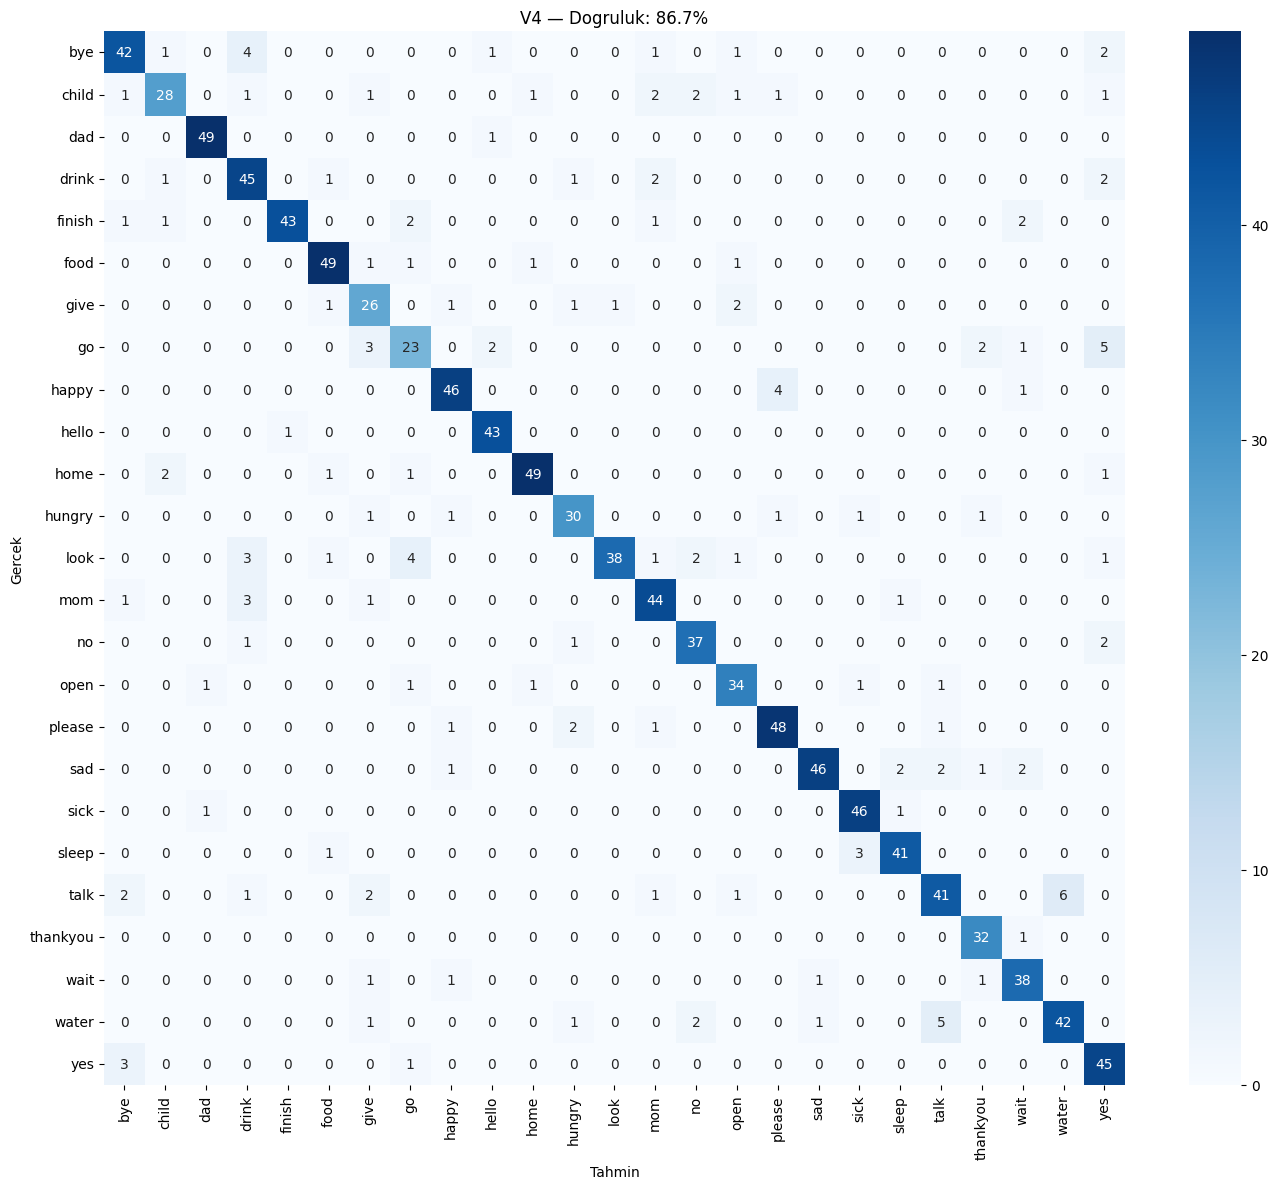

In [11]:
model.eval()
all_preds, all_true = [], []
with torch.no_grad():
    for X_b, y_b in test_dl:
        X_b = X_b.to(device)
        with torch.amp.autocast('cuda', enabled=use_amp):
            out = model(X_b)
        all_preds.extend(out.argmax(1).cpu().numpy())
        all_true.extend(y_b.numpy())

target_names = [inv_map[i] for i in sorted(inv_map.keys())]
test_acc = accuracy_score(all_true, all_preds)
print(f"Test Dogruluk: {test_acc:.4f} ({test_acc:.1%})")
print()
print(classification_report(all_true, all_preds, target_names=target_names, zero_division=0))

cm = confusion_matrix(all_true, all_preds)
fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=target_names, yticklabels=target_names, ax=ax)
ax.set_xlabel("Tahmin"); ax.set_ylabel("Gercek")
ax.set_title(f"V4 — Dogruluk: {test_acc:.1%}")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix_v4.png"), dpi=150)
plt.show()

## 10. Model Kaydetme

In [12]:
from datetime import datetime

model_path = os.path.join(OUTPUT_DIR, "word_model_v4.pt")
torch.save(model.state_dict(), model_path)
print(f"Model: {model_path} ({os.path.getsize(model_path)/1024/1024:.2f} MB)")

lm_path = os.path.join(OUTPUT_DIR, "word_label_map_v4.json")
with open(lm_path, "w") as f:
    json.dump(label_map, f, indent=2)

meta = {
    "version": "V4",
    "num_features": NUM_FEATURES,
    "num_landmarks": NUM_LANDMARKS,
    "landmark_breakdown": {
        "right_hand": NUM_RIGHT_HAND, "left_hand": NUM_LEFT_HAND,
        "face": NUM_FACE, "pose": NUM_POSE,
        "face_indices": FACE_INDICES, "pose_indices": POSE_INDICES,
    },
    "sequence_length": SEQUENCE_LENGTH,
    "hidden_size": HIDDEN_SIZE,
    "num_layers": NUM_LAYERS,
    "dropout": DROPOUT,
    "bidirectional": BIDIRECTIONAL,
    "model_type": "GRU",
    "accuracy": float(test_acc),
    "classes": num_classes,
    "target_words": sorted(TARGET_WORDS),
    "normalization": "shoulder_centric",
    "trained_at": datetime.now().isoformat(),
    "improvements": [
        "Focal Loss (gamma=2)",
        "Attention Pooling",
        "Mixup augmentation",
        "CosineAnnealingWarmRestarts",
        "AdamW (weight_decay=1e-4)",
        "Higher dropout (0.4)",
        "Higher label smoothing (0.15)",
        "More aggressive augmentation",
    ],
}
meta_path = os.path.join(OUTPUT_DIR, "word_model_meta_v4.json")
with open(meta_path, "w") as f:
    json.dump(meta, f, indent=2, ensure_ascii=False)

print(f"\n{'='*60}")
print("  V4 MODELI HAZIR")
print(f"{'='*60}")
print("Indirme dosyalari:")
print("  - word_model_v4.pt")
print("  - word_label_map_v4.json")
print("  - word_model_meta_v4.json")
print(f"Test dogrulugu: {test_acc:.1%}")

Model: /kaggle/working/word_model_v4.pt (2.72 MB)

  V4 MODELI HAZIR
Indirme dosyalari:
  - word_model_v4.pt
  - word_label_map_v4.json
  - word_model_meta_v4.json
Test dogrulugu: 86.7%
